# Lab 9 - Gyroscope parameters identification



In [3]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # upload the whole /data dir

Saving gyro_hand_spin.csv to gyro_hand_spin.csv
Saving gyro_hand_spin_cc_fast.csv to gyro_hand_spin_cc_fast.csv
Saving gyro_hand_spin_cc_fast_2.csv to gyro_hand_spin_cc_fast_2.csv
Saving gyro_hand_spin_cc_slow.csv to gyro_hand_spin_cc_slow.csv
Saving gyro_hand_spin_cw_fast.csv to gyro_hand_spin_cw_fast.csv
Saving gyro_hand_spin_cw_fast_2.csv to gyro_hand_spin_cw_fast_2.csv
Saving gyro_hand_spin_cw_slow.csv to gyro_hand_spin_cw_slow.csv
Saving gyro_spin.csv to gyro_spin.csv
Saving gyro_spin_chirp.csv to gyro_spin_chirp.csv
Saving gyro_spin_reverse.csv to gyro_spin_reverse.csv
Saving gyro_static.csv to gyro_static.csv
Saving gyro_static_calib.csv to gyro_static_calib.csv
Saving odometry_data.csv to odometry_data.csv
Saving odometry_data_2.csv to odometry_data_2.csv


## 1. Offset (bias) - $b_0$

In [4]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy.stats import norm

st = pd.read_csv('gyro_static.csv')
st['t'] = (st.t_ms - st.t_ms.iloc[0]) / 1000   # s
st['w'] = st.wz / 1000                         # deg/s
first = st[st.t < 30]

b0 = first.w.mean()
sigma = first.w.std()

std_error = sigma / np.sqrt(len(first))
print(f'N (first 30 s) = {len(first)}')
print(f'b0 = {b0:.3f} ± {std_error:.3f} deg/s (mean ± standard error)')


N (first 30 s) = 157
b0 = 0.920 ± 0.006 deg/s (mean ± standard error)


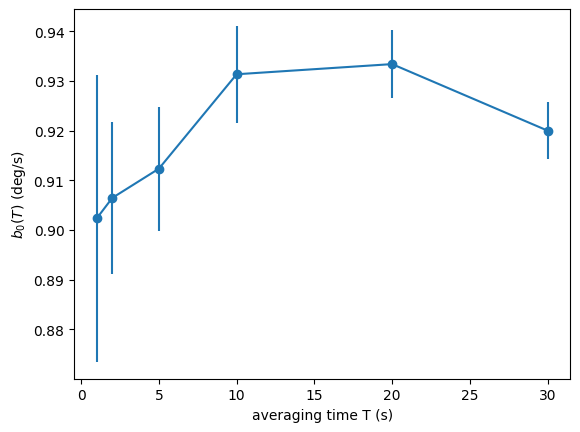

In [5]:
Ts = [1, 2, 5, 10, 20, 30]      # averaging time T, s
b0_T, se_T = [], []
for T in Ts:
    part = st[st.t < T]                              # rows from the first T seconds
    b0_T.append(part.w.mean())                       # b0 for this T
    se_T.append(part.w.std() / np.sqrt(len(part)))   # its standard error
plt.errorbar(Ts, b0_T, yerr=se_T, fmt='o-')
plt.xlabel('averaging time T (s)'); plt.ylabel('$b_0(T)$ (deg/s)')
plt.show()


$b_0 = 0.920 \pm 0.006$ deg/s. Below 10 s the estimate is noisy, from 10 s to 20 s it stays at $\approx 0.93$ deg/s, and by 30 s it is lower again, since the bias starts to drift ($\S 2$). Therefore, I recommend calibrating for 10-20 s.

## 2. Bias drift - $d$

          t_mid         b
win                      
0     15.026671  0.920000
1     45.118333  0.843406
2     74.947675  0.786637
3    105.045312  0.765357
4    135.058743  0.737401
5    164.976163  0.735295
d = -0.072 deg/s per min


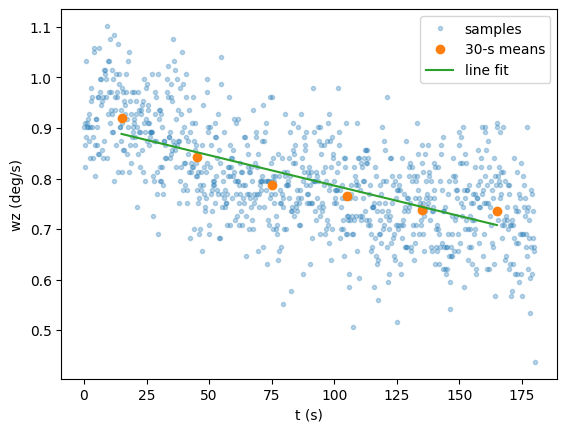

In [6]:
st['win'] = (st.t // 30).astype(int)       # window number: 0 for 0–30 s, 1 for 30–60 s, and so on
wm = st.groupby('win').agg(t_mid=('t', 'mean'), b=('w', 'mean'))
wm = wm[wm.index < 6]                       # the six full windows (drops the last row, at 180.2 s)
print(wm)

d, c = np.polyfit(wm.t_mid / 60, wm.b, 1)   # fit the line b = d·t + c, with t in minutes
print(f'd = {d:.3f} deg/s per min')

plt.plot(st.t, st.w, '.', alpha=0.3, label='samples')
plt.plot(wm.t_mid, wm.b, 'o', label='30-s means')
plt.plot(wm.t_mid, d * wm.t_mid / 60 + c, '-', label='line fit')
plt.xlabel('t (s)'); plt.ylabel('wz (deg/s)'); plt.legend(); plt.show()

raw heading drift: 47.3 deg/min (b0·60 = 55.2 deg/min)
t = 60 s: raw 52.9 deg, b0 removed -2.3 deg
t = 120 s: raw 99.5 deg, b0 removed -10.9 deg
t = 180 s: raw 143.7 deg, b0 removed -21.9 deg


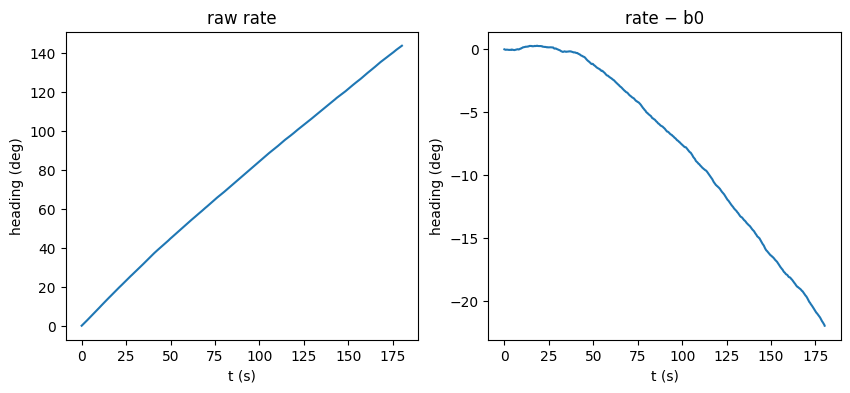

In [7]:
from scipy.integrate import cumulative_trapezoid

st['th_raw'] = cumulative_trapezoid(st.w, st.t, initial=0)        # heading from the raw rate, deg
st['th_cor'] = cumulative_trapezoid(st.w - b0, st.t, initial=0)   # heading with b0 subtracted, deg

slope = np.polyfit(st.t / 60, st.th_raw, 1)[0]
print(f'raw heading drift: {slope:.1f} deg/min (b0·60 = {b0*60:.1f} deg/min)')
for T in (60, 120, 180):
    print(f't = {T} s: raw {np.interp(T, st.t, st.th_raw):.1f} deg, '
          f'b0 removed {np.interp(T, st.t, st.th_cor):.1f} deg')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(st.t, st.th_raw); ax[0].set_title('raw rate')
ax[1].plot(st.t, st.th_cor); ax[1].set_title('rate − b0')
for a in ax:
    a.set_xlabel('t (s)'); a.set_ylabel('heading (deg)')
plt.show()

$d = -0.072$ deg/s per min. The 30-s means fall fast at first and then level off, so a straight line is only a rough model. The raw heading drifts by 47.3 deg/min, less than $b_0 \cdot 60 = 55.2$ deg/min, since the bias falls during the log: its average is $\approx 0.80$ deg/s, not 0.92. Even with $b_0$ subtracted, the heading is off by $-21.9$ deg after 180 s, about 50 times more than white noise alone would give (0.42 deg). A possible reason (a hypothesis) is temperature (Woodman 3.2.4); it was not tested.

## 3. Measurement range - $\omega_{max}$

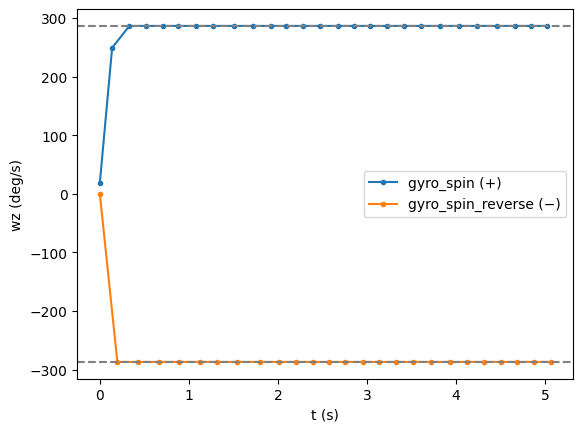

+w_max = 286.685 deg/s (5.004 rad/s), 25 of 27 rows
−w_max = -286.790 deg/s (-5.005 rad/s), 25 of 26 rows


In [8]:
sp = pd.read_csv('gyro_spin.csv')
sp['t'] = (sp.t_ms - sp.t_ms.iloc[0]) / 1000   # s
sp['w'] = sp.wz / 1000                         # deg/s

rv = pd.read_csv('gyro_spin_reverse.csv')
rv['t'] = (rv.t_ms - rv.t_ms.iloc[0]) / 1000   # s
rv['w'] = rv.wz / 1000                         # deg/s

plt.plot(sp.t, sp.w, '.-', label='gyro_spin (+)')
plt.plot(rv.t, rv.w, '.-', label='gyro_spin_reverse (−)')
plt.axhline(sp.w.max(), ls='--', c='gray')
plt.axhline(rv.w.min(), ls='--', c='gray')
plt.xlabel('t (s)'); plt.ylabel('wz (deg/s)'); plt.legend(); plt.show()

w_pos = sp.w.max()
n_pos = (sp.w == w_pos).sum()
w_neg = rv.w.min()
n_neg = (rv.w == w_neg).sum()


print(f'+w_max = {w_pos:.3f} deg/s ({np.radians(w_pos):.3f} rad/s), {n_pos} of {len(sp)} rows')
print(f'−w_max = {w_neg:.3f} deg/s ({np.radians(w_neg):.3f} rad/s), {n_neg} of {len(rv)} rows')


$\omega_{max} \approx \pm 286.7$ deg/s ($\pm 5.00$ rad/s). The reading stays flat at the limit in both spins, so the robot turned faster than the gyro can measure. The limit is the 16-bit output: $32767 \times 8.75$ mdeg/s $= 286.71$ deg/s, within 0.1 deg/s of the measured values.

## 4. Resolution - $\Delta$

In [9]:
vals = np.sort(st.wz.unique())       # the distinct values in the log, mdeg/s
steps = np.diff(vals)                # the gaps between neighbouring values
print(vals[:12])
print(pd.Series(steps).value_counts())

[437 507 516 533 542 551 560 568 577 586 595 603]
9     49
8     15
17     2
70     1
Name: count, dtype: int64


$\Delta = 8.75$ mdeg/s. The log shows steps of 8 and 9 mdeg/s (15 and 49 times), since the robot rounds each value down to whole mdeg/s, which gives the pattern 8, 9, 9, 9. $\Delta$ is about 8 times smaller than $\sigma$ ($\S 5$), so the rounding hardly matters.

## 5. Noise - $\sigma$

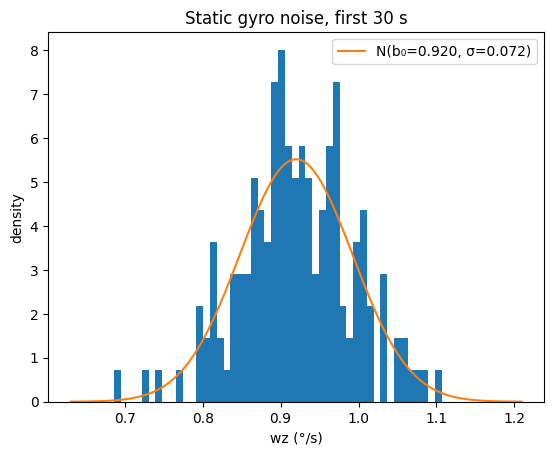

sigma = 0.072 deg/s (sample std, first 30 s)
extremes: -3.17 sigma, 2.52 sigma
beyond 3 sigma: 1 of 157
P(|z| > 3) = 0.0027, expected beyond 3 sigma: 0.42 of 157


In [10]:
D = 0.00875                                     # resolution, deg/s
k_lo = np.floor(first.w.min() / D)
k_hi = np.ceil(first.w.max() / D)
bins = (np.arange(k_lo, k_hi + 2) - 0.5) * D
plt.hist(first.w, bins=bins, density=True)

x = np.linspace(b0 - 4*sigma, b0 + 4*sigma, 200)
plt.plot(x, norm.pdf(x, b0, sigma), label=f'N(b₀={b0:.3f}, σ={sigma:.3f})')
plt.xlabel('wz (°/s)')
plt.ylabel('density')
plt.title('Static gyro noise, first 30 s')
plt.legend()
plt.show()

z = (first.w - b0) / sigma
print(f'sigma = {sigma:.3f} deg/s (sample std, first 30 s)')
print(f'extremes: {z.min():.2f} sigma, {z.max():.2f} sigma')
print(f'beyond 3 sigma: {(abs(z) > 3).sum()} of {len(first)}')

p3 = 2 * norm.sf(3)
expected = len(first) * p3
print(f'P(|z| > 3) = {p3:.4f}, expected beyond 3 sigma: {expected:.2f} of {len(first)}')

$\sigma = 0.072$ deg/s. Only 1 of 157 samples is beyond $3\sigma$, while 0.42 are expected for normal noise, and the chance of at least one is $\approx 35\%$. So it is not an outlier, the noise is consistent with a normal distribution, and I did not remove any samples.

## 6. Scale factor - $s$

gyro_hand_spin_cc_slow.csv: bias 0.150 deg/s, angle 1084.0 deg, s = +0.37 %
gyro_hand_spin_cw_slow.csv: bias 0.158 deg/s, angle -1083.6 deg, s = +0.33 %


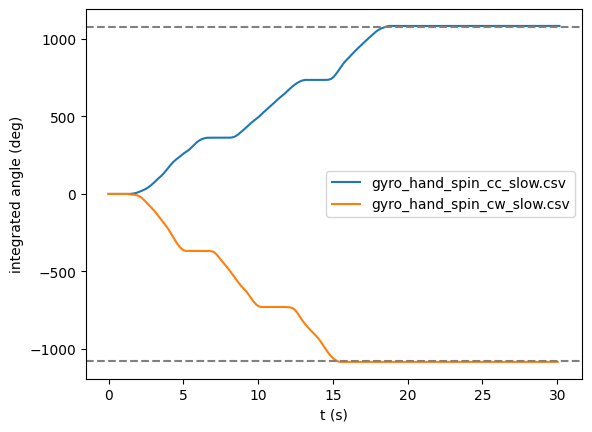

In [11]:
def turn_angle(fname):
    d = pd.read_csv(fname)
    d['t'] = (d.t_ms - d.t_ms.iloc[0]) / 1000      # s
    d['w'] = d.wz / 1000                            # deg/s
    moving = d.w.abs() > 3                          # rows where the robot turns
    first = moving.idxmax()                         # first moving row
    last = moving[::-1].idxmax()                    # last moving row
    rest = pd.concat([d.loc[:first - 1], d.loc[last + 1:]])   # at rest before and after
    bias = rest.w.mean()
    theta = cumulative_trapezoid(d.w - bias, d.t, initial=0)  # deg
    return d, bias, theta

for fname, theta_true in [('gyro_hand_spin_cc_slow.csv', 1080),
                          ('gyro_hand_spin_cw_slow.csv', -1080)]:
    run, bias, theta = turn_angle(fname)
    s = theta[-1] / theta_true - 1
    print(f'{fname}: bias {bias:.3f} deg/s, angle {theta[-1]:.1f} deg, s = {s*100:+.2f} %')
    plt.plot(run.t, theta, label=fname)

plt.axhline(1080, ls='--', c='gray'); plt.axhline(-1080, ls='--', c='gray')
plt.xlabel('t (s)'); plt.ylabel('integrated angle (deg)'); plt.legend(); plt.show()


CCW is positive, since the CCW run gave $+1084.0$ deg for three turns (CW: $-1083.6$ deg). $s = +0.37\%$ (CCW) and $+0.33\%$ (CW), so in both directions the gyro shows $\approx 4$ deg more than 1080 deg. However, stopping by hand is accurate to an estimated 3 deg ($0.28\%$), and the same sign in both directions could also come from overshooting by hand. So $|s| \lesssim 0.37\% + 0.28\% \approx 0.65\%$ is only an upper bound; in $\S 7$ I used $s = +0.35\%$.

## 7. Simulated gyro

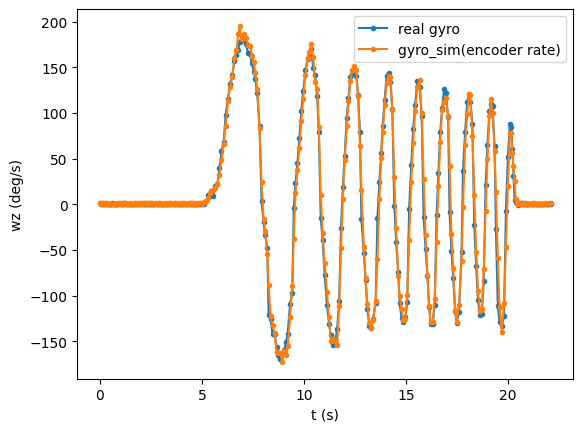

at rest: real 0.781, sim 0.925 deg/s
real − sim, sd over the run: 11.0 deg/s


In [12]:

B0, SIGMA = b0, sigma           # deg/s
DRIFT = d / 60                  # deg/s per second
W_MAX, DELTA = 286.7, 0.00875   # deg/s
S = 0.0035                      # scale-factor error, 0.35 %
rng = np.random.default_rng(0)

def gyro_sim(omega_true, t):
    w = (1 + S) * omega_true + B0 + DRIFT * t + rng.normal(0, SIGMA, len(t))
    w = np.clip(w, -W_MAX, W_MAX)            # saturation
    return np.round(w / DELTA) * DELTA       # quantisation

od = pd.read_csv('odometry_data_2.csv')
od['t'] = (od.t - od.t.iloc[0]) / 1000                 # s
od['w'] = od.wz / 1000                                 # real gyro, deg/s
r, B = 0.042, 0.194                                    # wheel radius, track width (m)
od['th_enc'] = r / B * (od.encR - od.encL)             # encoder heading, deg
od['w_enc'] = np.gradient(od.th_enc, od.t)             # encoder rate = omega_true
od['w_sim'] = gyro_sim(od.w_enc.values, od.t.values)

plt.plot(od.t, od.w, '.-', label='real gyro')
plt.plot(od.t, od.w_sim, '.-', label='gyro_sim(encoder rate)')
plt.xlabel('t (s)'); plt.ylabel('wz (deg/s)'); plt.legend(); plt.show()

rest = od.t < 5                                   # robot at rest
print(f'at rest: real {od.w[rest].mean():.3f}, sim {od.w_sim[rest].mean():.3f} deg/s')
print(f'real − sim, sd over the run: {(od.w - od.w_sim).std():.1f} deg/s')

`gyro_sim` takes a true rate and the sample times, and returns what the gyro would read: the true rate with the errors from $\S 1$-$\S 6$ added. As the true rate I used the encoder rate from `odometry_data_2.csv`.

The simulation follows the real log, but $\omega_{real} - \omega_{sim}$ has a standard deviation of 11.0 deg/s, against $\sigma = 0.072$ deg/s for the noise alone, mostly at the reversals. The reason is the encoder rate: the encoders assume the wheels don't slip, but at a reversal they do (a hypothesis; not tested).

At rest the real gyro reads 0.781 deg/s and the simulation 0.925 deg/s. The gap is 24 standard errors of $b_0$, so the bias changed between runs, and it would add 8.6 deg of heading error per minute. Therefore, one `calibrate()` is not enough: we need to recalibrate at the start of each run.

## 8. Parameter table

| Parameter | Symbol | Value | Unit | Method |
|---|---|---|---|---|
| Offset | $b_0$ | $0.920 \pm 0.006$ | deg/s | mean of the first 30 s of `gyro_static.csv`, $\pm$ standard error |
| Bias drift | $d$ | $-0.072$ | deg/s per min | line fit to the six 30-s window means of `gyro_static.csv` |
| Heading drift, uncorrected | - | 47.3 | deg/min | slope of the heading integrated from the raw rate, `gyro_static.csv` |
| Range | $\pm\omega_{max}$ | $+286.685$ / $-286.790$ | deg/s | max of `gyro_spin.csv` / min of `gyro_spin_reverse.csv`, where the reading stays flat |
| Resolution | $\Delta$ | 8.75 | mdeg/s | gaps between neighbouring values of `wz` in `gyro_static.csv` (8 and 9, rounded down), checked with $32767 \times 8.75 = 286.71$ deg/s |
| Noise | $\sigma$ | 0.072 | deg/s | sample std of the first 30 s of `gyro_static.csv`; over all 3 min the bias drift ($\S 2$) adds to the spread ($\approx 0.10$), so 30 s gives the noise alone |
| Raw -> deg/s factor | - | 0.001 | (deg/s)/(mdeg/s) | logged the gyroscope block's values (mdeg/s), so `wz / 1000`; `readRawData()` was not logged, so the ratio method was not done; mdeg/s confirmed by saturation at $32767 \times 8.75$ mdeg/s |
| Scale factor CCW / CW | $s$ | $+0.37$ / $+0.33$ | % | integrated angle (rest bias removed) of `gyro_hand_spin_cc_slow.csv` and `gyro_hand_spin_cw_slow.csv` against $\pm 1080$ deg; upper bound only, $\lvert s \rvert \lesssim 0.65\%$, limited by the hand stop |
| Positive rotation direction | - | CCW | - | `gyro_hand_spin_cc_slow.csv` integrates to $+1084.0$ deg |


## 9. Encoder vs gyro heading

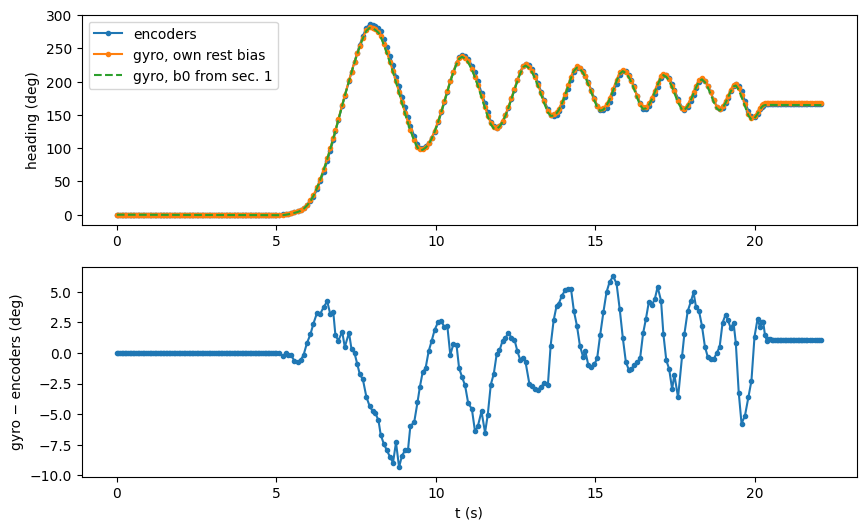

rest bias 0.782 deg/s; final heading: encoders 166.7, gyro 167.8, gyro with b0 164.7 deg


In [13]:
odo = pd.read_csv('odometry_data_2.csv')
odo['ts'] = (odo.t - odo.t.iloc[0]) / 1000                       # s
odo_bias = (odo.wz[odo.ts < 4] / 1000).mean()                    # this run's own rest bias, deg/s
odo['h_enc'] = r / B * (odo.encR - odo.encL)                     # deg (r, B from sec. 7)
odo['h_gyro'] = cumulative_trapezoid(odo.wz / 1000 - odo_bias, odo.ts, initial=0)
odo['h_gyro_b0'] = cumulative_trapezoid(odo.wz / 1000 - b0, odo.ts, initial=0)   # sec. 1's b0 instead

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(odo.ts, odo.h_enc, '.-', label='encoders')
plt.plot(odo.ts, odo.h_gyro, '.-', label='gyro, own rest bias')
plt.plot(odo.ts, odo.h_gyro_b0, '--', label='gyro, b0 from sec. 1')
plt.ylabel('heading (deg)'); plt.legend()
plt.subplot(2, 1, 2)
plt.plot(odo.ts, odo.h_gyro - odo.h_enc, '.-')
plt.xlabel('t (s)'); plt.ylabel('gyro − encoders (deg)'); plt.show()
print(f'rest bias {odo_bias:.3f} deg/s; final heading: encoders {odo.h_enc.iloc[-1]:.1f}, '
      f'gyro {odo.h_gyro.iloc[-1]:.1f}, gyro with b0 {odo.h_gyro_b0.iloc[-1]:.1f} deg')

In [14]:
xyz = pd.read_csv('gyro_static.csv')
print((xyz[['wx', 'wy', 'wz']] / 1000).agg(['mean', 'std']).round(3))

         wx      wy     wz
mean -0.795  12.711  0.798
std   0.094   0.071  0.103


gyro_hand_spin_cc_fast_2.csv: angle 1057.7 deg, s = -2.06 %, peak 286.7 deg/s, saturated rows 3
gyro_hand_spin_cw_fast_2.csv: angle -1065.6 deg, s = -1.33 %, peak 286.4 deg/s, saturated rows 0


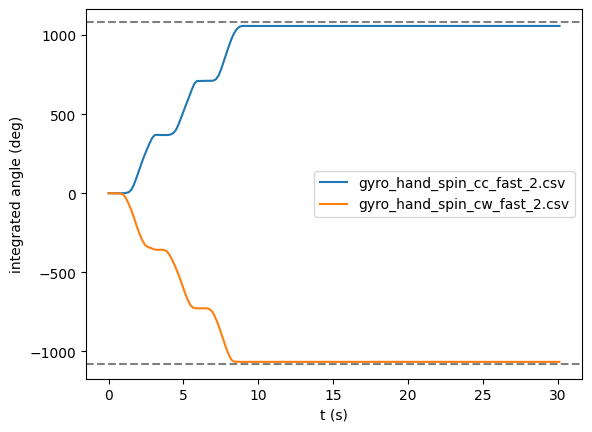

In [15]:
for fname_fast, true_angle in [('gyro_hand_spin_cc_fast_2.csv', 1080),
                               ('gyro_hand_spin_cw_fast_2.csv', -1080)]:
    fast, fast_bias, fast_theta = turn_angle(fname_fast)
    s_fast = fast_theta[-1] / true_angle - 1
    print(f'{fname_fast}: angle {fast_theta[-1]:.1f} deg, s = {s_fast*100:+.2f} %, '
          f'peak {fast.w.abs().max():.1f} deg/s, saturated rows {(fast.w.abs() > 286.6).sum()}')
    plt.plot(fast.t, fast_theta, label=fname_fast)
plt.axhline(1080, ls='--', c='gray'); plt.axhline(-1080, ls='--', c='gray')
plt.xlabel('t (s)'); plt.ylabel('integrated angle (deg)'); plt.legend(); plt.show()

## 12. Error analysis

In [16]:

b0_1s = first.groupby(first.t.astype(int)).w.mean()     # b0 from each 1 s of the first 30 s
se20 = sigma / np.sqrt((st.t < 20).sum())                 # standard error of b0 from 20 s
print(f'1 s:  sd {b0_1s.std():.3f} deg/s -> {b0_1s.std()*60:.1f} deg/min (worst {(b0_1s - b0).abs().max()*60:.1f})')
print(f'20 s: standard error {se20:.3f} deg/s -> {se20*60:.1f} deg/min')

cal = pd.read_csv('gyro_static_calib.csv')
cal['t'] = (cal.t_ms - cal.t_ms.iloc[0]) / 1000          # s
cal['w'] = cal.wz / 1000                                 # deg/s
after = cal[cal.t >= 30]                                 # calibrate() is applied at 30 s (wy drops from 12.4 to 0)
th_cal = cumulative_trapezoid(after.w, after.t, initial=0)
print(f'wz before {cal.w[cal.t < 30].mean():.3f}, after {after.w.mean():.3f} deg/s')
for T in (60, 120, 150):
    print(f'{T} s after calibrate(): heading {np.interp(T, after.t - 30, th_cal):.1f} deg')


dt = st.t.diff().median()                                # sample period, s
for t in (10, 60, 180):
    print(f't = {t} s: no calibration {b0*t:.1f}, b0 from another run {(b0 - odo_bias)*t:.1f}, '
          f'1-s calibration {b0_1s.std()*t:.1f}, 20-s calibration {se20*t:.1f}, '
          f'drift {np.interp(t, st.t, st.th_cor):.1f}, noise {sigma*np.sqrt(dt*t):.1f} deg')
print(f'scale factor: {S*90:.1f} deg per 90 deg turned')


1 s:  sd 0.035 deg/s -> 2.1 deg/min (worst 4.7)
20 s: standard error 0.007 deg/s -> 0.4 deg/min
wz before 0.355, after 0.025 deg/s
60 s after calibrate(): heading 0.1 deg
120 s after calibrate(): heading 3.0 deg
150 s after calibrate(): heading 3.8 deg
t = 10 s: no calibration 9.2, b0 from another run 1.4, 1-s calibration 0.3, 20-s calibration 0.1, drift 0.1, noise 0.1 deg
t = 60 s: no calibration 55.2, b0 from another run 8.3, 1-s calibration 2.1, 20-s calibration 0.4, drift -2.3, noise 0.2 deg
t = 180 s: no calibration 165.6, b0 from another run 24.9, 1-s calibration 6.2, 20-s calibration 1.3, drift -21.9, noise 0.4 deg
scale factor: 0.3 deg per 90 deg turned


At 10 s the bias dominates (9.2 deg) unless it is removed; after calibration every error is below 0.5 deg for a 90-deg turn. At 1 min and 3 min the bias drift dominates ($-2.3$ and $-21.9$ deg), since it grows with $t^2$, while the noise grows only with $\sqrt{t}$.

| Heading error (deg) | 10 s | 1 min | 3 min |
|---|---|---|---|
| Bias, not calibrated ($b_0 t$) | 9.2 | 55.2 | 165.6 |
| $b_0$ from another run ($\S 1$ in the $\S 9$ run) | 1.4 | 8.3 | 24.9 |
| Calibration error, 1 s | 0.3 | 2.1 | 6.2 |
| Calibration error, 20 s | 0.1 | 0.4 | 1.3 |
| Drift, $b_0$ removed ($\S 2$) | 0.1 | $-2.3$ | $-21.9$ |
| Noise, $\sigma \sqrt{T_s t}$ | 0.1 | 0.2 | 0.4 |
| Scale factor, $s = 0.35\%$ | 0.3 per 90 deg turned | | |

1. **10 s.** Without calibration the heading is off by 9.2 deg. With it, the largest errors are the scale factor and the 1-s calibration (0.3 deg each); noise and drift are $\approx 0.1$ deg. So for short moves the gyro is very accurate.
2. **1 min.** The drift ($-2.3$ deg) dominates, and the 1-s calibration adds about as much (2.1 deg); with 20 s it is 0.4 deg. A $b_0$ from another run is worse than both (8.3 deg).
3. **3 min.** The drift ($-21.9$ deg) is 50 times the noise. In `gyro_static_calib.csv` it was smaller after `calibrate()` (3.0 deg after 2 min, against $-10.9$ deg in $\S 2$) and of the other sign, so the drift changes between sessions, and a fixed $d$ cannot remove it. A possible reason (a hypothesis) is warm-up (temperature, $\S 2$), since the bias in $\S 2$ fell fast at first and then levelled off; it was not tested.
4. **Saturation** is a separate limit: above 286.7 deg/s the gyro loses angle ($\S 3$, $\S 6$), so turns must stay below it (the $\S 7$ run stayed under 200 deg/s).

For runs up to about 1 min, `calibrate()` does the job, if it is called at the start of every run with the robot still (20 s): the error is then $\approx 2$-3 deg. For 3 min, it is weak: `calibrate()` removes one constant, but the bias keeps drifting (22 deg in $\S 2$). Therefore, for long runs I would recalibrate every time the robot stops, or combine the gyro with the encoders.